# PyVBMC Example 8: Fitting a PyMC model

In this notebook, we fit a model written in [PyMC](https://www.pymc.io/) with PyVBMC, return the posterior to PyMC and [ArviZ](https://www.arviz.org/) for analysis and prediction, and compare the results with those of NUTS, the No-U-Turn Sampler that PyMC uses by default ([Hoffman and Gelman, 2014](https://jmlr.org/papers/v15/hoffman14a.html)).

PyMC models are usually fit with NUTS, a Hamiltonian Monte Carlo method, which evaluates the log density of the model and its gradient many thousands of times. PyVBMC needs far fewer evaluations and no gradients, so it is worth using when each evaluation of the model is expensive, as when the likelihood solves differential equations or calls external code, or when you also want an estimate of the model evidence, which NUTS does not provide. The model in this notebook is cheap, so that the notebook runs in seconds and its results can be checked.

This notebook is Part 8 of a series of notebooks in which we present various example usages for VBMC with the PyVBMC package. The code used in this example is available as a script [here](https://github.com/acerbilab/pyvbmc/blob/main/examples/scripts/pyvbmc_example_8_full_code.py). The PyMC integration needs Python 3.12 or newer and the optional `pymc` dependencies, installed with `pip install --upgrade "pyvbmc[pymc]"`.

In [1]:
import sys

if "google.colab" in sys.modules:  # Colab lacks PyVBMC: install it
    %pip install --upgrade "pyvbmc[pymc]"

In [2]:
import arviz as az
import numpy as np
import pandas as pd
import pymc as pm
import scipy.stats as scs
from scipy.integrate import quad

from pyvbmc import PyMCTarget, VBMC

SEED = 7  # Fix the seed, so that the results below are reproducible

## 1. A regression model in PyMC

We simulate 30 observations $y_i$ from a linear regression on a predictor $x_i$, with intercept $\beta_0 = 0.5$, slope $\beta_1 = 1$ and Gaussian noise of standard deviation $\sigma = 0.7$. Our model assigns priors to these three parameters:

$$
y_i \sim \mathcal{N}\left(\beta_0 + \beta_1 x_i, \sigma^2\right), \qquad
\beta_0, \beta_1 \sim \mathcal{N}\left(0, 5^2\right), \qquad
\sigma \sim \operatorname{HalfNormal}(2).
$$

In PyMC, the intercept and the slope form one vector variable, `beta`, and the coordinate `coef` labels its two entries `intercept` and `slope`. The deterministic variable `mu` stores the mean of each observation.

In [3]:
rng = np.random.default_rng(SEED)
n_observations = 30
predictor = np.linspace(-1.0, 1.0, n_observations)
design = np.column_stack([np.ones(n_observations), predictor])
beta_true = np.array([0.5, 1.0])
sigma_true = 0.7
observed = design @ beta_true + rng.normal(
    0.0, sigma_true, size=n_observations
)

coords = {
    "coef": ["intercept", "slope"],
    "observation": np.arange(n_observations),
}
with pm.Model(coords=coords) as model:
    beta = pm.Normal("beta", mu=0.0, sigma=5.0, dims="coef")
    sigma = pm.HalfNormal("sigma", sigma=2.0)
    mu = pm.Deterministic("mu", design @ beta, dims="observation")
    pm.Normal(
        "y",
        mu=mu,
        sigma=sigma,
        observed=observed,
        dims="observation",
    )

## 2. From the PyMC model to PyVBMC

In Examples 1 and 2, we set up PyVBMC by hand: we wrote the log-joint as a function, chose the hard and plausible bounds, and picked a starting point, ideally near the mode of the posterior. `PyMCTarget` does all of this from the PyMC model:

- the target is the model's log-joint density, priors included;
- the hard bounds follow from the support of each parameter;
- the starting point is the mode of the log-joint, found by a short optimization, and the plausible bounds extend three standard deviations on either side of it, as estimated from the curvature of the log-joint at the mode.

Printing the target shows how PyVBMC sees the parameters of the model:

In [4]:
target = PyMCTarget(model, seed=SEED)
print(target)

variable | shape | VBMC coordinates | kept transform | hard bounds | plausible bounds | start
beta | (2,) | beta[intercept], beta[slope] | - | [[-inf -inf], [inf inf]] | [[-0.09952025  0.24172931], [0.52304277 1.28427527]] | [0.21176126 0.76300229]
sigma | () | sigma_log__ | LogTransform | [[-inf], [inf]] | [[-0.95859605], [-0.1711322]] | [-0.56486412]


PyVBMC works with a flat vector of parameters, so the vector `beta` becomes the two coordinates `beta[intercept]` and `beta[slope]`. Since `sigma` is positive, PyVBMC works with its logarithm, `sigma_log__`, as PyMC's own samplers do; the target includes the Jacobian of this change of variables, which leaves the model evidence unchanged. All three coordinates are then unbounded, and the plausible bounds and the starting point of `sigma` are on the log scale.

The setup evaluates the model a few times. PyVBMC counts these evaluations toward its budget (the option `max_fun_evals`), and reuses their results.

## 3. Run PyVBMC

We pass the target to `VBMC` in place of the log-joint, the bounds and the starting point, and run the inference with the default options:

In [5]:
vbmc = VBMC(target, seed=SEED)
vp, results = vbmc.optimize()

Beginning variational optimization assuming EXACT observations of the log-joint.
Performance settings: saved calibration.
Tip: Run VBMC 3–4 times with different starting points. Compare the posterior plots across runs; large differences can indicate that a run missed part of the posterior.
https://acerbilab.org/pyvbmc/_examples/pyvbmc_example_4_validation.html
 Iteration f-count/f-cache    Mean[ELBO]     Std[ELBO]     sKL-iter[q]   K[q]  Convergence    Action
     0         9  /    9         -33.12          0.48      69128.12        2        inf       start warm-up
     1        14  /    9         -35.04          0.04          1.59        2        inf       
     2        19  /    9         -34.92          0.03          0.03        2       1.12       
     3        24  /    9         -34.91          0.01          0.04        2      0.739       
     4        29  /    9         -34.92          0.00          0.01        2      0.177       end warm-up
     5        34  /    9         -34.

The output is the iteration trace described in Example 2, with one more column: `f-cache` counts the evaluations of the setup that PyVBMC reused, and `f-count` counts PyVBMC's own evaluations. The last line gives the total number of evaluations used, including those of the setup (`initialization`), and the budget.

As in Example 1, two especially relevant statistics are the ELBO, a lower bound on the log model evidence $\log p(\mathcal{D})$, and its uncertainty. For this model, we can compute the exact log evidence for comparison. Given $\sigma$, the coefficients integrate out analytically: the observations are jointly Gaussian, $\mathbf{y} \mid \sigma \sim \mathcal{N}\left(\mathbf{0}, \sigma^2 \mathbf{I} + 5^2 \mathbf{X} \mathbf{X}^\top\right)$, where $\mathbf{X}$ is the design matrix. A one-dimensional integral over the prior of $\sigma$ remains, which we compute numerically:

In [6]:
def log_evidence_given_sigma(s):
    """log p(y | sigma), with the coefficients integrated out."""
    cov = s**2 * np.eye(n_observations) + 5.0**2 * design @ design.T
    return scs.multivariate_normal(np.zeros(n_observations), cov).logpdf(
        observed
    )


# Factor out exp(shift), so that the integrand is of order one:
shift = log_evidence_given_sigma(sigma_true)
integral, _ = quad(
    lambda s: np.exp(log_evidence_given_sigma(s) - shift)
    * scs.halfnorm(scale=2.0).pdf(s),
    0,
    np.inf,
)
lml_true = shift + np.log(integral)

print("The true log model evidence is:", format(lml_true, ".3f"))
print("The obtained ELBO is:", format(results["elbo"], ".3f"))
print("The obtained ELBO_SD is:", format(results["elbo_sd"], ".3f"))

The true log model evidence is: -34.910
The obtained ELBO is: -34.909
The obtained ELBO_SD is: 0.001


The ELBO is very close to the true log model evidence. The model evidence is the basis of Bayesian model comparison: to compare models fit to the same data, compare their ELBOs.

## 4. Back to PyMC

To analyze the posterior with PyMC and ArviZ, `target.to_arviz` draws samples from the variational posterior and returns them as an ArviZ `DataTree`, under the model's own variable names, shapes and coordinates, with `sigma` back on its original scale. ArviZ summarizes them as it would the draws of a PyMC sampler:

In [7]:
posterior_data = target.to_arviz(vp, n_samples=4000)
vbmc_summary = az.summary(
    posterior_data,
    var_names=["beta", "sigma"],
    kind="stats",  # MCMC diagnostics do not apply to independent draws
    round_to=3,
)
vbmc_summary

,mean,sd,eti89_lb,eti89_ub
beta[intercept],0.213,0.112,0.034,0.388
beta[slope],0.770,0.183,0.470,1.067
sigma,0.607,0.086,0.489,0.759


PyMC's own functions accept these samples too. `pm.compute_deterministics` adds the deterministic variable `mu` to every sample, and `pm.sample_posterior_predictive` draws replicated observations from the model. For each observation, ordered by the predictor, the plot shows the mean and the 50% and 90% intervals of the replicated values, and the observed value as a black dot:

Sampling: [y]


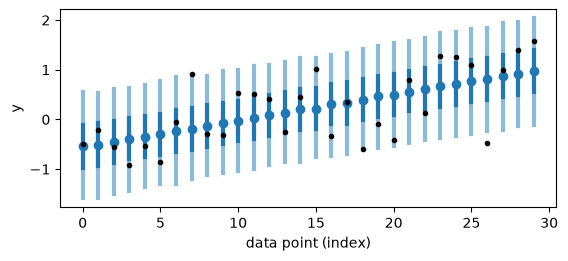

In [8]:
posterior_data = pm.compute_deterministics(
    posterior_data,
    model=model,
    var_names=["mu"],
    extend_dataset=True,  # keep beta and sigma beside mu
    progressbar=False,
)
posterior_predictive = pm.sample_posterior_predictive(
    posterior_data,
    model=model,
    var_names=["y"],
    random_seed=SEED,
    progressbar=False,
)
az.plot_ppc_interval(
    posterior_predictive,
    var_names=["y"],
    point_estimate="mean",
    ci_probs=(0.5, 0.9),
);

## 5. Comparison with NUTS

For a model as cheap as this one, PyMC's NUTS sampler is the natural reference. We run it with PyMC's default settings, with the four chains one after the other (`cores=1`), and set its summary beside PyVBMC's:

In [9]:
with model:
    nuts_data = pm.sample(
        chains=4, cores=1, random_seed=SEED, progressbar=False
    )

nuts_summary = az.summary(
    nuts_data, var_names=["beta", "sigma"], kind="stats", round_to=3
)
pd.concat({"PyVBMC": vbmc_summary, "NUTS": nuts_summary}, axis=1)

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [beta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


PyVBMC                            NUTS                  \
                  mean     sd eti89_lb eti89_ub   mean     sd eti89_lb   
beta[intercept]  0.213  0.112    0.034    0.388  0.208  0.112    0.030   
beta[slope]      0.770  0.183    0.470    1.067  0.767  0.183    0.475   
sigma            0.607  0.086    0.489    0.759  0.604  0.086    0.483   

                          
                eti89_ub  
beta[intercept]    0.386  
beta[slope]        1.051  
sigma              0.751

The two posteriors agree. Their costs differ: for each draw, NUTS follows a trajectory of several steps, and each step evaluates the log density and its gradient.

In [10]:
n_gradients = int(nuts_data.sample_stats["n_steps"].sum())
print(
    "PyVBMC evaluations of the log density:",
    results["evaluation_budget"]["used"],
)
print("NUTS evaluations of the log density and its gradient:", n_gradients)

PyVBMC evaluations of the log density: 81
NUTS evaluations of the log density and its gradient: 12600


The count for NUTS leaves out its tuning steps, which PyMC does not keep. Each evaluation of this model takes microseconds, so NUTS is the better choice here, and it comes with its own convergence diagnostics. When an evaluation takes seconds or minutes, or provides no gradient, the difference between fewer than a hundred evaluations and more than ten thousand is what makes PyVBMC worth using.

## 6. Conclusions

In this notebook, we have fit a PyMC model with PyVBMC. `PyMCTarget` sets up the inference from the model, and `target.to_arviz` returns the posterior to PyMC and ArviZ for summaries and predictions. The ELBO matched the exact log model evidence, and the posterior matched that of NUTS, with a small fraction of the evaluations that NUTS needed.

`PyMCTarget` handles models with continuous parameters; its [documentation](https://acerbilab.org/pyvbmc/api/classes/pymc_target.html) lists the models it supports and the options of its setup. The target keeps a copy of the data it was built with, so to fit new data, build a new target. As with any model, validate the results with multiple runs of PyVBMC, as in Example 4.

## Acknowledgments

Work on the PyVBMC package is supported by the Research Council of Finland (grants 356498 and 358980 to Luigi Acerbi) and its Flagship programme: [Finnish Center for Artificial Intelligence FCAI](https://fcai.fi/).